# 08 - Density sweep

**Owner:** Member 1
**Task:** Does LightGCN's advantage over BPR-MF, on each test, depend on how dense the training graph is? Keep 100/50/25/10% of the training interactions at random and train both models at the settings notebooks 03 and 04 selected. Validation and both test sets stay fixed. Score every model on the biased test (Recall@20, NDCG@20) and on the unbiased test (exposure-only GAUC and NDCG@5; full-ranking Recall@20 as a second row). Record users, items, edges, density and the cold users each level creates. Secondary variant: 5-core and 10-core filtering.
**Inputs:** `data/processed/*.npz` (notebook 02), selected settings from `results/03_mf_parameters.json` and `results/04_lightgcn_parameters_*.json`, `src/experiments/density_sweep.py`
**Outputs:** `results/08_density_sweep.json`, `results/08_density_sweep.png`, `results/08_density_sweep_summary.csv`, `results/08_density_sweep_gap.csv`

After running: save the numbers to `results/`, append an entry to `LOG.md`, and write the matching report section.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image
import data
import inference
from experiments import density_sweep as sweep
from utils.io import save_json, savefig

SEED = 0  # one seed first (compute budget); notebook 06 gives the seed-to-seed spread at full density
DATASETS = ("kuairand", "kuairec")
LABELS = {"kuairand": "KuaiRand-Pure", "kuairec": "KuaiRec", "mf": "BPR-MF", "lightgcn": "LightGCN",
          "pop": "Most-popular"}
KEEP = [f"keep={x}" for x in sweep.LEVELS]
CORE = [f"core={k}" for k in sweep.CORES]

## Setup
Each model runs at the settings its own study selected on validation Recall@20, as in notebook 06 (BPR-MF from 03, LightGCN from 04, per dataset); batch 2048, max 100 epochs, evaluation every 5 epochs, early stopping with patience 4 on validation Recall@20, which stays the full validation set at every level. The unbiased tests are never used for stopping (fairness rule 9).

The runs are long (a full-density LightGCN run takes over an hour on CPU), so they were trained by `src/experiments/density_sweep.py` in four background processes, one per physical core. Every finished run is cached in `results/08_density_<dataset>_<variant>.json` and this notebook reads that cache. Set `TRAIN_MISSING = True` to train any run that is missing here instead (hours on CPU).

In [2]:
configs = {name: sweep.selected_configs(name) for name in DATASETS}
display(pd.DataFrame([dict(dataset=LABELS[n], **dict(c, model=LABELS[m])) for n in DATASETS for m, c in configs[n].items()]))

TRAIN_MISSING = False
if TRAIN_MISSING:
    for name in DATASETS:
        for v in KEEP + CORE:
            sweep.run_variant(name, v, seed=SEED)
runs = {k: r for k, r in sweep.load_sweep().items() if r["seed"] == SEED}
print(len(runs), "runs")

,dataset,model,dim,lr,reg,batch,epochs,layers
0,KuaiRand-Pure,BPR-MF,64,0.0010,0.0010,2048,100,NaN
1,KuaiRand-Pure,LightGCN,128,0.0010,0.0001,2048,100,3.0
2,KuaiRec,BPR-MF,64,0.0003,0.0001,2048,100,NaN
3,KuaiRec,LightGCN,128,0.0010,0.0001,2048,100,3.0


18 runs


Most-popular reference at each level: items ranked by their training degree in that variant, scored with the same evaluation code (no training). It anchors the question of the project: how far above popularity each model sits as the graph gets sparser.

In [3]:
class Popularity:
    """Scores every item by its training degree; same interface as the trained models for inference."""
    def __init__(self, ds):
        self.n_users, self.deg = ds["n_users"], torch.tensor(data.degrees(ds)[1], dtype=torch.float32)

    def eval(self):
        return self

    def embeddings(self):
        return torch.ones(self.n_users, 1), self.deg[:, None]


for name in DATASETS:
    full = data.load_processed(name, SEED)
    for v in KEEP + CORE:
        ds = sweep.variant(full, v, SEED)
        pop = Popularity(ds)
        runs[f"{name}|{v}|pop|seed={SEED}"] = dict(
            dataset=name, variant=v, model="pop", seed=SEED, stats=sweep.graph_stats(ds),
            test=inference.evaluate(pop, ds, "test", mask_splits=("train", "val"))[0],
            test_unbiased=inference.evaluate(pop, ds, "test_unbiased", mask_splits=("train", "val", "test"))[0],
            test_exposed=inference.evaluate_exposed(pop, ds)[0])

rows = []
for r in runs.values():
    s, t, u, e = r["stats"], r["test"], r["test_unbiased"], r["test_exposed"]
    rows.append(dict(dataset=r["dataset"], variant=r["variant"], model=r["model"], edges=s["train"], density=s["density"],
                     train_users=s["train_users"], train_items=s["train_items"], users=s["users"], items=s["items"],
                     cold_users=s["cold_users"], cold_users_unbiased=s.get("cold_users_unbiased"), cold_items=s["cold_items"],
                     recall=t["recall"], ndcg=t["ndcg"], coverage=t["coverage"], popularity=t["popularity"],
                     gauc=e["gauc"], ndcg5=e["ndcg"], recall_unbiased=u["recall"], ndcg_unbiased=u["ndcg"],
                     recall_warm=r.get("recall_warm"), recall_cold=r.get("recall_cold"),
                     gauc_warm=r.get("gauc_warm"), gauc_cold=r.get("gauc_cold"),
                     best_epoch=r.get("best_epoch"), epochs_run=r.get("epochs_run"), time_s=r.get("train_time")))
df = pd.DataFrame(rows)
df["variant"] = pd.Categorical(df.variant, KEEP + CORE, ordered=True)
df["model"] = pd.Categorical(df.model, ["pop", "mf", "lightgcn"], ordered=True)
df = df.sort_values(["dataset", "variant", "model"]).reset_index(drop=True)

## Random subsampling of training interactions
Validation, both tests and the id space stay fixed, so users and items that lose all their training pairs become cold and are still evaluated. The graph at each level:

In [4]:
graph = df[df.model == "mf"].set_index(["dataset", "variant"])[
    ["edges", "density", "train_users", "train_items", "cold_users", "cold_users_unbiased", "cold_items"]]
graph.style.format({"density": "{:.3%}"})

Every model at every level. Biased test: Recall@20 and NDCG@20 (full ranking). Unbiased test: GAUC and NDCG@5 over each user's shown videos (exposure-only protocol), then full-ranking Recall@20. Warm/cold split the users of each test by whether they kept any training pair.

In [5]:
cols = ["recall", "ndcg", "gauc", "ndcg5", "recall_unbiased", "coverage", "popularity",
        "recall_warm", "recall_cold", "gauc_warm", "gauc_cold", "best_epoch", "time_s"]
summary = df.set_index(["dataset", "variant", "model"])[cols]
summary[summary.index.get_level_values("variant").isin(KEEP)].round(4)

recall    ndcg    gauc   ndcg5  recall_unbiased  \
dataset  variant   model                                                       
kuairand keep=1.0  pop       0.1141  0.0761  0.5828  0.3621           0.0067   
                   mf        0.1693  0.1102  0.6123  0.3995           0.0060   
                   lightgcn  0.2179  0.1461  0.6140  0.4067           0.0063   
         keep=0.5  pop       0.1104  0.0721  0.5814  0.3621           0.0064   
                   mf        0.1047  0.0709  0.5847  0.3705           0.0049   
                   lightgcn  0.1591  0.1056  0.6032  0.3940           0.0053   
         keep=0.25 pop       0.1085  0.0704  0.5808  0.3609           0.0063   
                   mf        0.0536  0.0367  0.5502  0.3338           0.0041   
                   lightgcn  0.1283  0.0854  0.5876  0.3781           0.0055   
         keep=0.1  pop       0.1063  0.0701  0.5770  0.3588           0.0062   
                   mf        0.0299  0.0196  0.5039  0.2902           0.0044   
                   lightgcn  0.0762  0.0546  0.5461  0.3348           0.0057   
kuairec  keep=1.0  pop       0.0736  0.0877  0.7612  0.6752           0.1503   
                   mf        0.1066  0.1145  0.7721  0.6068           0.1731   
                   lightgcn  0.1255  0.1361  0.7333  0.5517           0.1634   
         keep=0.5  pop       0.0672  0.0749  0.7612  0.6752           0.1524   
                   mf        0.0862  0.0879  0.7542  0.5884           0.1590   
                   lightgcn  0.0994  0.1025  0.7349  0.5997           0.1699   
         keep=0.25 pop       0.0653  0.0700  0.7596  0.6765           0.1586   
                   mf        0.0598  0.0641  0.6888  0.4190           0.0882   
                   lightgcn  0.0824  0.0839  0.7510  0.6457           0.1682   
         keep=0.1  pop       0.0623  0.0660  0.7529  0.6221           0.1519   
                   mf        0.0228  0.0289  0.5224  0.1913           0.0265   
                   lightgcn  0.0698  0.0737  0.6965  0.5456           0.1378   

                             coverage  popularity  recall_warm  recall_cold  \
dataset  variant   model                                                      
kuairand keep=1.0  pop         0.0053   2064.2757          NaN          NaN   
                   mf          0.6164    820.1618       0.1693          NaN   
                   lightgcn    0.4903    923.1558       0.2179          NaN   
         keep=0.5  pop         0.0044   1055.3997          NaN          NaN   
                   mf          0.6635    508.3370       0.1087       0.0211   
                   lightgcn    0.4709    536.2538       0.1655       0.0237   
         keep=0.25 pop         0.0039    537.7483          NaN          NaN   
                   mf          0.4860    218.4000       0.0579       0.0250   
                   lightgcn    0.3534    344.8787       0.1423       0.0356   
         keep=0.1  pop         0.0035    215.2041          NaN          NaN   
                   mf          0.3717     64.3703       0.0301       0.0295   
                   lightgcn    0.3660    149.3315       0.0907       0.0445   
kuairec  keep=1.0  pop         0.0047   1110.3807          NaN          NaN   
                   mf          0.1684    707.1028       0.1066          NaN   
                   lightgcn    0.2695    641.9449       0.1255          NaN   
         keep=0.5  pop         0.0036    572.8549          NaN          NaN   
                   mf          0.1597    414.1753       0.0863       0.0000   
                   lightgcn    0.2647    359.7147       0.0994       0.0769   
         keep=0.25 pop         0.0030    291.3909          NaN          NaN   
                   mf          0.2614    208.7638       0.0600       0.0404   
                   lightgcn    0.0743    219.3034       0.0827       0.0478   
         keep=0.1  pop         0.0025    119.5185          NaN          NaN   
                   mf          0.3246     51.3237   

LightGCN minus BPR-MF at each level, and each model's margin over most-popular, on both tests. One seed: a gap is only meaningful against the seed-to-seed spread that notebook 06 measures at full density.

In [6]:
wide = df.pivot_table(index=["dataset", "variant"], columns="model", values=["recall", "gauc"], observed=True)
gap = pd.DataFrame({
    "recall_mf": wide["recall", "mf"], "recall_lightgcn": wide["recall", "lightgcn"],
    "recall_gain": wide["recall", "lightgcn"] - wide["recall", "mf"],
    "recall_rel_gain": wide["recall", "lightgcn"] / wide["recall", "mf"] - 1,
    "recall_mf_over_pop": wide["recall", "mf"] - wide["recall", "pop"],
    "recall_lightgcn_over_pop": wide["recall", "lightgcn"] - wide["recall", "pop"],
    "gauc_mf": wide["gauc", "mf"], "gauc_lightgcn": wide["gauc", "lightgcn"],
    "gauc_gain": wide["gauc", "lightgcn"] - wide["gauc", "mf"],
    "gauc_mf_over_pop": wide["gauc", "mf"] - wide["gauc", "pop"],
    "gauc_lightgcn_over_pop": wide["gauc", "lightgcn"] - wide["gauc", "pop"]})
gap.round(4)

recall_mf  recall_lightgcn  recall_gain  recall_rel_gain  \
dataset  variant                                                               
kuairand keep=1.0      0.1693           0.2179       0.0486           0.2869   
         keep=0.5      0.1047           0.1591       0.0543           0.5188   
         keep=0.25     0.0536           0.1283       0.0747           1.3935   
         keep=0.1      0.0299           0.0762       0.0462           1.5451   
         core=5           NaN              NaN          NaN              NaN   
         core=10       0.1768              NaN          NaN              NaN   
kuairec  keep=1.0      0.1066           0.1255       0.0189           0.1773   
         keep=0.5      0.0862           0.0994       0.0132           0.1535   
         keep=0.25     0.0598           0.0824       0.0226           0.3775   
         keep=0.1      0.0228           0.0698       0.0471           2.0672   
         core=5           NaN              NaN          NaN              NaN   
         core=10       0.1074              NaN          NaN              NaN   

                    recall_mf_over_pop  recall_lightgcn_over_pop  gauc_mf  \
dataset  variant                                                            
kuairand keep=1.0               0.0553                    0.1039   0.6123   
         keep=0.5              -0.0057                    0.0487   0.5847   
         keep=0.25             -0.0549                    0.0198   0.5502   
         keep=0.1              -0.0763                   -0.0301   0.5039   
         core=5                    NaN                       NaN      NaN   
         core=10                0.0681                       NaN   0.6191   
kuairec  keep=1.0               0.0330                    0.0519   0.7721   
         keep=0.5               0.0190                    0.0322   0.7542   
         keep=0.25             -0.0055                    0.0170   0.6888   
         keep=0.1              -0.0396                    0.0075   0.5224   
         core=5                    NaN                       NaN      NaN   
         core=10                0.0349                       NaN   0.7445   

                    gauc_lightgcn  gauc_gain  gauc_mf_over_pop  \
dataset  variant                                                 
kuairand keep=1.0          0.6140     0.0017            0.0295   
         keep=0.5          0.6032     0.0185            0.0033   
         keep=0.25         0.5876     0.0374           -0.0306   
         keep=0.1          0.5461     0.0422           -0.0732   
         core=5               NaN        NaN               NaN   
         core=10              NaN        NaN            0.0441   
kuairec  keep=1.0          0.7333    -0.0388            0.0109   
         keep=0.5          0.7349    -0.0193           -0.0070   
         keep=0.25         0.7510     0.0622           -0.0709   
         keep=0.1          0.6965     0.1741           -0.2305   
         core=5               NaN        NaN               NaN   
         core=10              NaN        NaN           -0.0026   

                    gauc_lightgcn_over_pop  
dataset  variant                            
kuairand keep=1.0                   0.0313  
         keep=0.5                   0.0218  
         keep=0.25                  0.0068  
         keep=0.1                  -0.0310  
         core=5                        NaN  
         core=10                       NaN  
kuairec  keep=1.0                  -0.0279  
         keep=0.5                  -0.0262  
         keep=0.25                 -0.0086  
         keep=0.1                  -0.0564  
         core=5                        NaN  
         core=10                       NaN

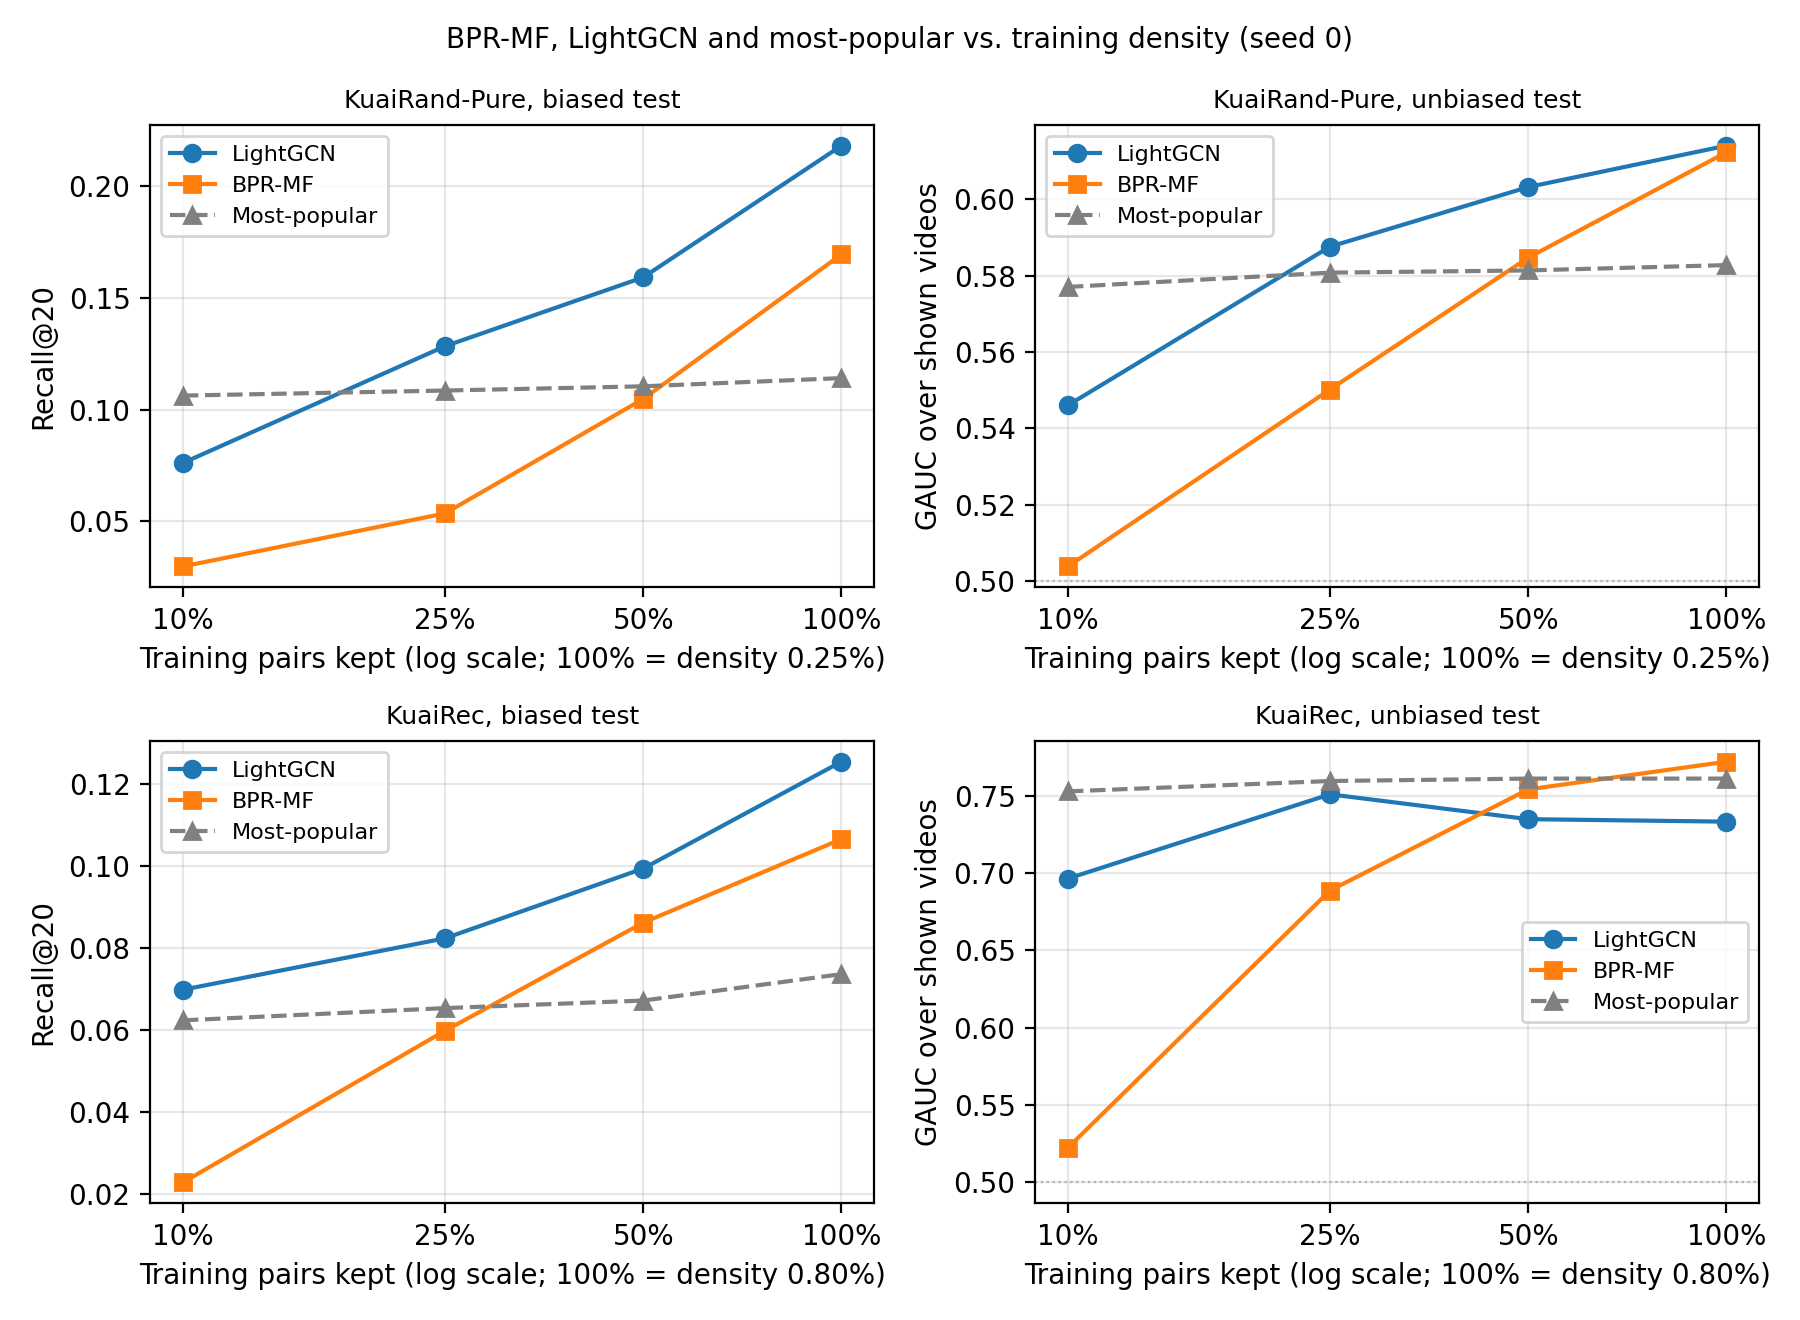

In [7]:
panels = [("recall", "biased test", "Recall@20"), ("gauc", "unbiased test", "GAUC over shown videos")]
fig, axes = plt.subplots(len(DATASETS), 2, figsize=(9, 3.3 * len(DATASETS)), squeeze=False)
sub = df[df.variant.isin(KEEP)].assign(kept=lambda d: d.variant.astype(str).str[5:].astype(float) * 100)
for row, name in zip(axes, DATASETS):
    full_density = sub[(sub.dataset == name) & (sub.kept == 100)].density.iloc[0]
    for ax, (metric, test, ylabel) in zip(row, panels):
        for model, style in (("lightgcn", "o-"), ("mf", "s-"), ("pop", "^--")):
            g = sub[(sub.dataset == name) & (sub.model == model)].sort_values("kept")
            ax.plot(g.kept, g[metric], style, label=LABELS[model], color="0.5" if model == "pop" else None)
        if metric == "gauc":
            ax.axhline(0.5, color="0.7", lw=0.8, ls=":")
        ax.set_xscale("log")
        ax.set_xticks([x * 100 for x in sweep.LEVELS], [f"{x:.0%}" for x in sweep.LEVELS])
        ax.minorticks_off()
        ax.set_xlabel(f"Training pairs kept (log scale; 100% = density {full_density:.2%})")
        ax.set_ylabel(ylabel)
        ax.set_title(f"{LABELS[name]}, {test}", fontsize=9)
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
fig.suptitle(f"BPR-MF, LightGCN and most-popular vs. training density (seed {SEED})", fontsize=10)
fig.tight_layout()
path = savefig(fig, "08_density_sweep.png")
plt.close(fig)
Image(filename=path)

## Secondary variant: k-core filtering
Removes users and items with fewer than k training pairs (iterated), so the user set, the item set and both tests shrink with it. These numbers are not comparable with the subsampling levels above; they ask the opposite question (a denser graph of the most active users and items).

In [8]:
display(df[(df.model == "mf") & df.variant.isin(["keep=1.0"] + CORE)].set_index(["dataset", "variant"])[
    ["users", "items", "edges", "density"]].style.format({"density": "{:.3%}"}))
core = summary[summary.index.get_level_values("variant").isin(["keep=1.0"] + CORE)]
core[["recall", "ndcg", "gauc", "ndcg5", "recall_unbiased", "coverage", "best_epoch", "time_s"]].round(4)

recall    ndcg    gauc   ndcg5  recall_unbiased  \
dataset  variant  model                                                       
kuairand keep=1.0 pop       0.1141  0.0761  0.5828  0.3621           0.0067   
                  mf        0.1693  0.1102  0.6123  0.3995           0.0060   
                  lightgcn  0.2179  0.1461  0.6140  0.4067           0.0063   
         core=5   pop       0.1114  0.0809  0.5777  0.4067           0.0084   
         core=10  pop       0.1087  0.0887  0.5750  0.4580           0.0106   
                  mf        0.1768  0.1350  0.6191  0.4999           0.0083   
kuairec  keep=1.0 pop       0.0736  0.0877  0.7612  0.6752           0.1503   
                  mf        0.1066  0.1145  0.7721  0.6068           0.1731   
                  lightgcn  0.1255  0.1361  0.7333  0.5517           0.1634   
         core=5   pop       0.0732  0.0882  0.7565  0.6744           0.1436   
         core=10  pop       0.0725  0.0898  0.7471  0.6742           0.1322   
                  mf        0.1074  0.1186  0.7445  0.6446           0.1600   

                            coverage  best_epoch      time_s  
dataset  variant  model                                       
kuairand keep=1.0 pop         0.0053         NaN         NaN  
                  mf          0.6164       100.0   1935.6791  
                  lightgcn    0.4903        95.0  10185.5452  
         core=5   pop         0.0072         NaN         NaN  
         core=10  pop         0.0095         NaN         NaN  
                  mf          0.7799        70.0    620.7479  
kuairec  keep=1.0 pop         0.0047         NaN         NaN  
                  mf          0.1684        75.0   1686.0687  
                  lightgcn    0.2695       100.0   9534.4566  
         core=5   pop         0.0076         NaN         NaN  
         core=10  pop         0.0095         NaN         NaN  
                  mf          0.2045        30.0    708.9280

## Save

In [9]:
save_json(dict(seed=SEED, settings=configs, levels=list(sweep.LEVELS), cores=list(sweep.CORES),
               protocol=dict(selection="validation Recall@20 (notebooks 03, 04)",
                             stopping="validation Recall@20, patience 4, every 5 epochs",
                             biased="full ranking, train+val masked",
                             unbiased_exposed="GAUC and NDCG@5 over each user's shown videos",
                             unbiased_full="full ranking, train+val+test masked; KuaiRec ranks block videos only",
                             pop="items ranked by training degree of the variant, no training"),
               runs=runs), "08_density_sweep.json")
summary.to_csv(os.path.join(sweep.RESULTS_DIR, "08_density_sweep_summary.csv"))
gap.to_csv(os.path.join(sweep.RESULTS_DIR, "08_density_sweep_gap.csv"))
print(sorted(f for f in os.listdir(sweep.RESULTS_DIR) if f.startswith("08_")))

['08_density_kuairand_core=10.json', '08_density_kuairand_keep=0.1.json', '08_density_kuairand_keep=0.25.json', '08_density_kuairand_keep=0.5.json', '08_density_kuairand_keep=1.0.json', '08_density_kuairec_core=10.json', '08_density_kuairec_keep=0.1.json', '08_density_kuairec_keep=0.25.json', '08_density_kuairec_keep=0.5.json', '08_density_kuairec_keep=1.0.json', '08_density_sweep.json', '08_density_sweep.png', '08_density_sweep_gap.csv', '08_density_sweep_summary.csv']


## Findings (random subsampling, seed 0)
At 100% both models reproduce notebooks 03 and 04 exactly (validation and biased-test Recall@20 to four decimals), so the sweep starts from the selected models.

**Biased test: the graph's lead grows as the graph gets sparser, because BPR-MF collapses.** LightGCN over BPR-MF in Recall@20 at 100/50/25/10% kept: +29% / +52% / +139% / +155% on KuaiRand-Pure and +18% / +15% / +38% / +207% on KuaiRec. BPR-MF falls below most-popular from 50% on KuaiRand (0.105 vs 0.110) and from 25% on KuaiRec (0.060 vs 0.065). LightGCN stays above most-popular down to 25% on KuaiRand (0.128 vs 0.109) and down to 10% on KuaiRec (0.070 vs 0.062), but not at 10% on KuaiRand (0.076 vs 0.106). Most-popular hardly moves (0.114 to 0.106; 0.074 to 0.062): random subsampling keeps the degree ranking of the items.

**Unbiased test (GAUC over shown videos): sparsity makes LightGCN beat BPR-MF, not popularity.** At 100% the graph adds nothing on KuaiRand (0.614 vs 0.612) and loses on KuaiRec (0.733 vs 0.772, where most-popular has 0.761). As the graph thins, LightGCN's GAUC lead over BPR-MF grows (KuaiRand +0.002 to +0.042; KuaiRec -0.039 to +0.174), but only because BPR-MF drops towards random (0.504 and 0.522 at 10%). Against most-popular, LightGCN's margin on KuaiRand shrinks from +0.031 at 100% to -0.031 at 10%, and on KuaiRec LightGCN is below most-popular at every level (closest at 25%: 0.751 vs 0.760). At 25% on KuaiRec LightGCN stops early (epoch 25) and ranks close to popularity (NDCG@5 0.646 vs most-popular's 0.677), which scores well on KuaiRec's popular block.

**Cold users.** At 10% kept, 8,092 of KuaiRand's biased-test users (31%) and 6,366 unbiased-test users lose every training pair; on KuaiRec only 335 and 243. For these users both models are at chance on the unbiased test (GAUC 0.49-0.51 on KuaiRand; 0.44-0.55 on KuaiRec, where the cold groups have only 11-243 users), so neither model has anything to offer a user the graph does not reach.

**Answer for the report.** LightGCN's advantage over BPR-MF depends strongly on density on both tests, and is largest when data is scarce. On the unbiased test that advantage is relative to a collapsing BPR-MF: LightGCN is never clearly above a most-popular ranking that needs no training. The graph mainly protects against collapse under sparsity; it does not find what users like beyond popularity.

**Caveats.** One seed; compare the gaps with notebook 06's seed spread at full density. Both models keep the settings selected at full density at every level (not re-tuned, the same for both). The 100-epoch cap binds for BPR-MF on KuaiRec at 25% and 10% (best epochs 95 and 100, because fewer pairs mean fewer updates per epoch); a check with 400 and 1,000 epochs (not saved, LOG.md 2026-10-11) leaves 25% unchanged (Recall@20 0.060, GAUC 0.689) and moves 10% from 0.023 to 0.027 Recall@20 and from 0.522 to 0.548 GAUC: no conclusion changes. k-core results are added when those runs finish.